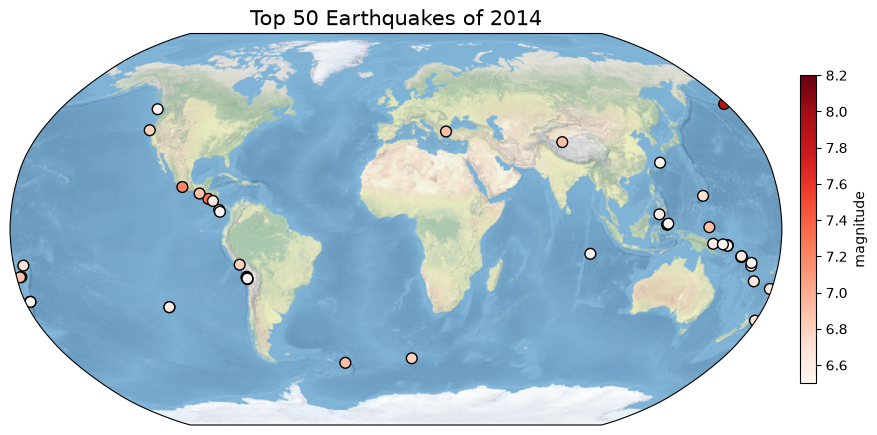

In [1]:
#PS4
#PS4_1
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

file_name = 'usgs_earthquakes.csv'
df = pd.read_csv(file_name)

#按mag震级从大到小排，取前50条
top50 = df.sort_values(by='mag', ascending=False).head(50)

plt.figure(figsize=(12, 8))

#Robinson 投影+地球背景图
ax = plt.axes(projection=ccrs.Robinson())
ax.stock_img()

#按经纬度打点
#x=经度, y=纬度, c=颜色(震级), transform=原始数据是经纬度，告诉程序转投影坐标
sc = ax.scatter(top50['longitude'], top50['latitude'],
                c=top50['mag'],                 
                s=60,                          # 点的大小
                cmap='Reds',                   # 红色系
                edgecolors='k',                # 黑边框
                transform=ccrs.PlateCarree())

#添加注释
plt.title('Top 50 Earthquakes of 2014', fontsize=15)

#添加色标
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.5, pad=0.02)
cbar.set_label('magnitude')

plt.savefig('output_1.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

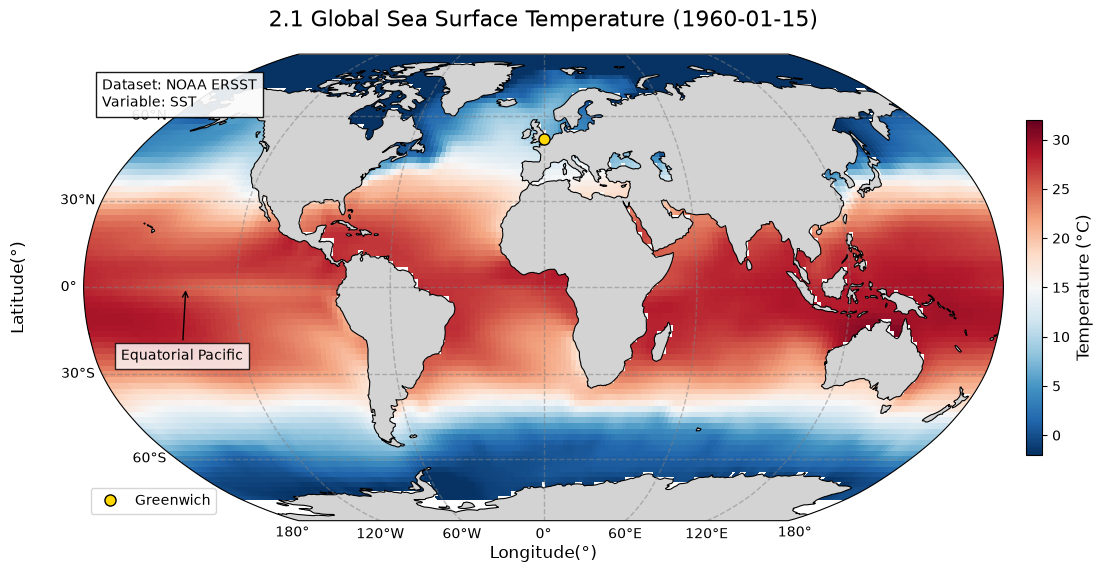

In [2]:
#PS4_2
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import matplotlib.ticker as mticker

#读取数据
file_path = 'NOAA_NCDC_ERSST_v3b_SST.nc'
ds = xr.open_dataset(file_path)

#提取第一个时间步的 SST (1960-01-15)
sst_data = ds['sst'].isel(time=0)
time_str = str(sst_data.time.values)[:10]

#2.1 Global Map
#Projection：用 Robinson 投影，全球范围
plt.figure(figsize=(12, 7))
proj = ccrs.Robinson()
ax = plt.axes(projection=proj)
ax.set_global()

#陆地掩膜和海岸线
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=1)
ax.coastlines(resolution='110m', linewidth=0.8, zorder=2)

#绘图SST，RdBu_r 配色，温度范围为-2到32
mesh = sst_data.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',     # 冷暖色调
    vmin=-2, vmax=32,
    add_colorbar=False,# 手动添加色标
    zorder=0
)

#网格线 → X轴名称刻度+Y轴名称刻度 → 标题 → 颜色条
gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=1,color='gray',
                  alpha=0.5,linestyle='--')

gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
gl.top_labels = False
gl.right_labels = False

ax.text(0.5, -0.08, 'Longitude(°)', transform=ax.transAxes, ha='center', fontsize=12)
ax.text(-0.08, 0.5, 'Latitude(°)', transform=ax.transAxes, rotation=90, va='center', fontsize=12)

plt.title(f'2.1 Global Sea Surface Temperature ({time_str})',
          fontsize=16, pad=20)

cbar = plt.colorbar(mesh, ax=ax,
                    orientation='vertical',
                    shrink=0.5, pad=0.02)
cbar.set_label('Temperature (°C)', fontsize=12)

#标注：箭头指向赤道太平洋定位
ax.annotate('Equatorial Pacific', xy=(-140, 0), xytext=(-170, -25),
            transform=ccrs.PlateCarree(), arrowprops=dict(arrowstyle='->', color='black'),
            fontsize=10, bbox=dict(facecolor='white', alpha=0.8))

#文本框：在左上角写明数据源和变量
ax.text(0.02, 0.95, 'Dataset: NOAA ERSST\nVariable: SST',
        transform=ax.transAxes, fontsize=10, verticalalignment='top',
        bbox=dict(facecolor='white', alpha=0.9))

#标个格林尼治位置，添加图例
ax.plot(0, 51.48, 'o', color='gold', markersize=8, markeredgecolor='black',
        transform=ccrs.PlateCarree(), label='Greenwich', zorder=10)
plt.legend(loc='lower left')
plt.tight_layout()

plt.savefig('output_2_1.png', dpi=300, bbox_inches='tight')
plt.show()

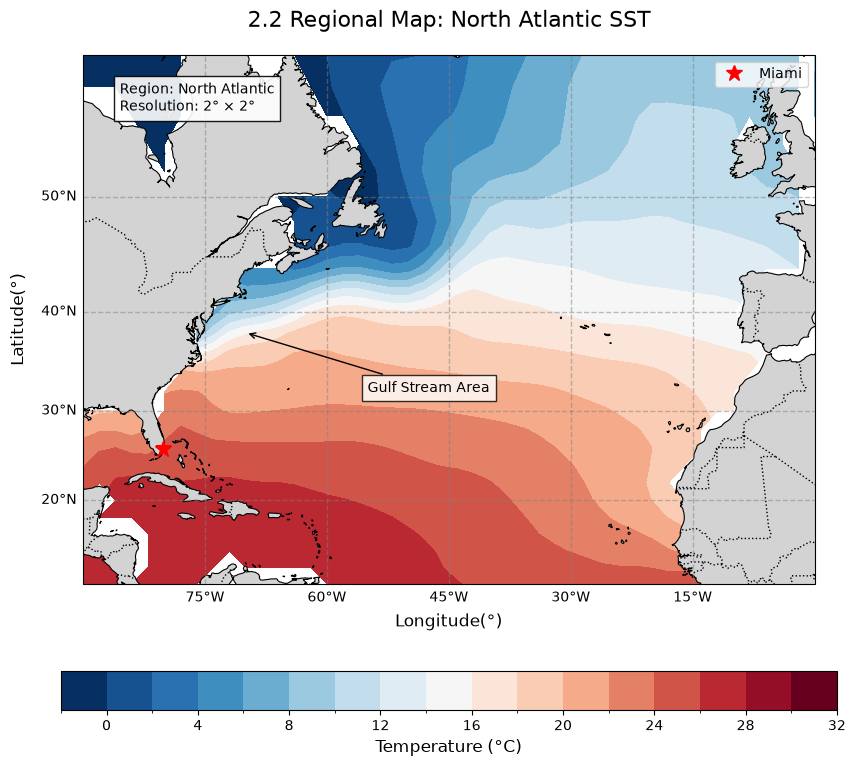

In [3]:
#2.2 Regional Map
plt.figure(figsize=(10, 8))

#Mercator 投影
proj2 = ccrs.Mercator()
ax2 = plt.axes(projection=proj2)

#选取北大西洋区域
extent = [-90, 0, 10, 60] #[西经, 东经, 南纬, 北纬]
ax2.set_extent(extent, crs=ccrs.PlateCarree())

#添加陆地、国界和海岸线
ax2.add_feature(cfeature.LAND, facecolor='lightgray', zorder=1)
ax2.add_feature(cfeature.BORDERS, linestyle=':', zorder=2)
ax2.coastlines(resolution='50m', linewidth=0.8, zorder=2)

#绘制等高线填色图
contour = sst_data.plot.contourf(ax=ax2, transform=ccrs.PlateCarree(),
        levels=np.linspace(-2, 32, 18), cmap='RdBu_r', add_colorbar=False, zorder=0)

#添加经纬度网格线 → X轴经度刻度+Y轴纬度刻度 → 标题 → 颜色条
gl2 = ax2.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=1,
                    color='gray', alpha=0.5, linestyle='--')

gl2.xlocator = mticker.FixedLocator(np.arange(-90, 1, 15))
gl2.ylocator = mticker.FixedLocator(np.arange(10, 61, 10))

gl2.top_labels = False
gl2.right_labels = False

ax2.text(0.5, -0.08, 'Longitude(°)', transform=ax2.transAxes,
         ha='center', fontsize=12)
ax2.text(-0.1, 0.5, 'Latitude(°)', transform=ax2.transAxes,
         rotation=90, va='center', fontsize=12)

plt.title('2.2 Regional Map: North Atlantic SST', fontsize=16, pad=20)

cbar2 = plt.colorbar(contour, ax=ax2, orientation='horizontal', shrink=0.8, pad=0.12)
cbar2.set_label('Temperature (°C)', fontsize=12)

#标注：用箭头标注墨西哥湾流区域
ax2.annotate('Gulf Stream Area', xy=(-70, 38), xytext=(-55, 32),
             transform=ccrs.PlateCarree(), arrowprops=dict(arrowstyle='->', color='black'),
             fontsize=10, bbox=dict(facecolor='white', alpha=0.8))

#文本框：研究区域和分辨率
ax2.text(0.05, 0.95, 'Region: North Atlantic\nResolution: 2° × 2°',
         transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', bbox=dict(facecolor='white', alpha=0.9))

#图例并标记迈阿密的位置
ax2.plot(-80.2, 25.8, 'r*', markersize=12, transform=ccrs.PlateCarree(),
         label='Miami', zorder=10)
plt.legend(loc='upper right')
plt.tight_layout()

plt.savefig('output_2_2.png', dpi=300, bbox_inches='tight')
plt.show()